# HW2 — Target-only 비교군과 고정 holdout 평가

**웹 Colab에 이 ipynb 업로드 → T4 GPU → Run All. Qwen2.5-1.5B 하나, 추가 학습 없음.**

코드·과거 원출력이 내장되어 추가 파일 업로드가 필요 없습니다. ① 개발 480입력에 **Target-only 숫자 출력 + 기존과 동일한 제약 관계 검증기**를 추가합니다. ② 방법을 고정한 뒤 새 개체·숫자 조합의 **holdout 1,152입력**에서 ID/Target-only/Standard와 각 gate 조합을 평가합니다.

Holdout은 **새 family 16개(task당 8개)**의 6조건 × 3문서 형식 × 2placement × 기존/변형 표현입니다. 1,152개가 독립 family인 것은 아닙니다. 두 표현은 같은 사실·배경을 공유합니다. 기존 literal parser와 모든 선언된 속성 표현을 아는 강한 schema-aware parser를 함께 평가합니다. 개발/holdout 결과는 별도 표와 통계로 저장합니다.

**새 holdout 모델 출력은 이 노트북에서 처음 생성합니다.** 전체 문맥 추론을 새로 실행하므로 이전 378회 실험보다 오래 걸립니다. CPU 준비 후 정확한 개발 추가 요청과 holdout 요청 상한을 표시합니다. 실행 전에 코드·자료·정답·prompt·parser를 잠그고, 결과를 보고 방법을 자동 변경하지 않습니다. 같은 합성 분포와 사전 선언한 문구 변화에 대한 평가이며 자연 문서·다른 모델의 일반화나 알고리즘 신규성을 확정하지 않습니다.

기본 `REUSE_PARENT=True`는 기록된 실행 환경이 같을 때 개발 원출력만 재사용합니다. 불일치 오류라면 설정 셀에서 False로 바꾸고 Run All 하세요. 개발 비교군도 새 폴더에서 다시 실행합니다. Holdout에는 과거 원출력을 사용하지 않습니다. Drive 미연결 시 마지막 ZIP을 내려받으세요. 기존 실행 노트북·ZIP은 보존합니다.


주 비교에는 **Target-only-routed + gate**를 사용합니다. ID 방식과 똑같이 target에 숫자가 없으면 CPU에서 null을 반환하고 모델을 호출하지 않습니다. 일반 Target-only + gate도 함께 저장해 호출 생략 효과를 구분합니다. 이 비교군은 같은 원출력을 공유하므로 새 GPU 요청을 늘리지 않습니다.


In [26]:
import platform, subprocess, sys
from pathlib import Path
if platform.system() != "Linux" or not Path("/content").is_dir():
    raise RuntimeError("웹 Colab에서 T4 GPU를 선택하세요. 로컬 모델 실행은 차단됩니다.")
import google.colab
print("Python:", sys.version.split()[0])
print(subprocess.run(["nvidia-smi"], capture_output=True, text=True, check=True).stdout)


Python: 3.13.16
Tue Nov 10 05:25:45 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   67C    P0             31W /   70W |     145MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-------------------------------

In [27]:
import base64, hashlib, json, sys, zlib
from pathlib import Path, PurePosixPath
CODE_ROOT = Path("/content/hw2_holdout_code")
SOURCES = json.loads(zlib.decompress(base64.b64decode('...')))
EXPECTED_BUNDLE = '9a73f1d3229c470015ab6aa3f17dba259ece63866a17ecd33e7c66374d3b5f4e'
if hashlib.sha256(json.dumps(SOURCES, sort_keys=True, ensure_ascii=False).encode()).hexdigest() != EXPECTED_BUNDLE:
    raise RuntimeError("Embedded source integrity failure")
for relative, content in SOURCES.items():
    rel = PurePosixPath(relative)
    if rel.is_absolute() or ".." in rel.parts:
        raise RuntimeError("Unsafe embedded path")
    path = CODE_ROOT / relative
    if not path.resolve().is_relative_to(CODE_ROOT.resolve()):
        raise RuntimeError("Embedded path escapes code root")
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_bytes(content.encode("utf-8"))
sys.path.insert(0, str(CODE_ROOT))
package = sys.modules.get("experiments")
if package is not None:
    if not hasattr(package, "__path__"):
        raise RuntimeError("Incompatible experiments module; restart the kernel")
    folder = str(CODE_ROOT / "experiments")
    package.__path__ = [folder] + [p for p in package.__path__ if p != folder]
for name in list(sys.modules):
    if name == "experiments.hw2_holdout_colab" or name.startswith("experiments.hw2_holdout_colab."):
        del sys.modules[name]
print("Embedded source ready:", CODE_ROOT, "|", EXPECTED_BUNDLE[:12])


Embedded source ready: /content/hw2_holdout_code | 9a73f1d3229c


In [28]:
import importlib, subprocess, sys
from importlib import metadata
for package, expected in (("transformers", "4.57.6"), ("tokenizers", "0.22.2")):
    if package in sys.modules and metadata.version(package) != expected:
        raise RuntimeError(package + " 버전이 이미 다르게 로드됐습니다. 커널 재시작 후 Run All 하세요.")
subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "--disable-pip-version-check", "-r",
               str(CODE_ROOT / "experiments/hw2_holdout_colab/requirements-colab.txt")], check=True)
importlib.invalidate_caches()
print("Transformers:", metadata.version("transformers"), "| tokenizers:", metadata.version("tokenizers"))


Transformers: 4.57.6 | tokenizers: 0.22.2


In [29]:
# Drive에 보관하려면 아래 두 줄의 주석을 해제하세요.
# from google.colab import drive
# drive.mount("/content/drive")
REUSE_PARENT = True  # 환경이 다르다는 오류가 나오면 False로 변경 후 Run All
DRIVE = Path("/content/drive/MyDrive")
RESULT_BASE = DRIVE / "hw2_holdout" if DRIVE.is_dir() else Path("/content/hw2_holdout")
RUN_NAME = "holdout_v1" + ("" if REUSE_PARENT else "_fresh")
RUN_DIR = RESULT_BASE / RUN_NAME
MODEL_CACHE = Path("/content/hw2_value_tracking_model_cache")
print("RESULTS:", RUN_DIR)
print("Reuse parent outputs:", REUSE_PARENT, "| Drive persistent:", DRIVE.is_dir())


RESULTS: /content/hw2_holdout/holdout_v1
Reuse parent outputs: True | Drive persistent: False


In [30]:
import unittest
suite = unittest.defaultTestLoader.discover(str(CODE_ROOT / "experiments/hw2_holdout_colab/tests"),
                                          pattern="test_*.py", top_level_dir=str(CODE_ROOT))
test_result = unittest.TextTestRunner(verbosity=1).run(suite)
if not test_result.wasSuccessful():
    raise RuntimeError("CPU checks failed; inference was not started")


..........
----------------------------------------------------------------------
Ran 10 tests in 0.051s

OK


In [31]:
from experiments.hw2_holdout_colab.runner import prepare
prepared = prepare(RUN_DIR, cache_dir=MODEL_CACHE, reuse_parent=REUSE_PARENT)
print(json.dumps(json.loads((RUN_DIR / "call_plan.json").read_text()), ensure_ascii=False, indent=2))


Parent CPU replay: 1 / 480
Parent CPU replay: 120 / 480
Parent CPU replay: 240 / 480
Parent CPU replay: 360 / 480
Parent CPU replay: 480 / 480
Historical CPU audit: 480 pointer + 480 gate decisions, 2000 raw records.
Inputs and rules frozen before model loading: 480 development + 1152 holdout | 3456b315a6d7
{
  "development_inputs": 480,
  "new_development_gate_calls_exact_if_reuse": 21,
  "holdout_inputs": 1152,
  "holdout_bases": 16,
  "holdout_unique_candidate_calls": 2208,
  "holdout_total_calls_upper_bound": 4416,
  "reuse_total_new_calls_upper_bound": 4437,
  "refresh_total_new_calls_upper_bound": 6192,
  "maximum_candidate_prompt_tokens": 2013,
  "holdout_history_request_hits": 0,
  "note": "Development reuse count is exact. Holdout gate candidates are unknown until inference; counts are conservative bounds, not runtime estimates."
}


In [32]:
from experiments.hw2_holdout_colab.engine import preflight
_, runtime = preflight(prepared["tok"], prepared["history"].setup, REUSE_PARENT)
print("Runtime check passed; no model loaded yet.")
print(json.dumps(runtime, indent=2))


Runtime check passed; no model loaded yet.
{
  "python": "3.13.16",
  "torch": "2.14.1+cu130",
  "transformers": "4.57.6",
  "tokenizers": "0.22.2",
  "cuda_build": "13.0",
  "gpu": "Tesla T4",
  "capability": [
    7,
    5
  ],
  "chat_template_hash": "2e2d2512cfe46af53dc1eed45368ecaab26ac4461c480e6b69fe571cf0ceaa75"
}


## 추론 실행

아래에서만 Qwen을 로드합니다. 입력을 먼저 모두 고정했으며, holdout 요청 상한은 실제 소요 시간이나 정확도 예측이 아닙니다. 동일 요청은 공유하고 invalid나 오답 때문에 재시도하지 않습니다. 중단 후 같은 코드·환경·설정에서 다시 실행하면 체크포인트를 사용합니다. 실제 새 생성량·시간·메모리와 입력당 논리적 비용도 저장합니다.


In [33]:
from experiments.hw2_holdout_colab.runner import run, archive
try:
    summary = run(RUN_DIR, cache_dir=MODEL_CACHE, reuse_parent=REUSE_PARENT, prepared=prepared)
finally:
    if RUN_DIR.exists():
        result_zip = archive(RUN_DIR)


Inputs 1 / 1632 | development | new calls 0
Inputs 24 / 1632 | development | new calls 0
Inputs 48 / 1632 | development | new calls 0
Inputs 72 / 1632 | development | new calls 0
Inputs 96 / 1632 | development | new calls 0
Inputs 120 / 1632 | development | new calls 0
Inputs 144 / 1632 | development | new calls 0
Inputs 168 / 1632 | development | new calls 0
Inputs 192 / 1632 | development | new calls 0
New generations: 1 | target_only_gate_constrained | constrained
Inputs 216 / 1632 | development | new calls 3
Inputs 240 / 1632 | development | new calls 5
Inputs 264 / 1632 | development | new calls 7
Inputs 288 / 1632 | development | new calls 10
Inputs 312 / 1632 | development | new calls 13
Inputs 336 / 1632 | development | new calls 15
Inputs 360 / 1632 | development | new calls 15
Inputs 384 / 1632 | development | new calls 15
Inputs 408 / 1632 | development | new calls 15
Inputs 432 / 1632 | development | new calls 15
Inputs 456 / 1632 | development | new calls 19
New generation

# HW2 Target-only 비교와 고정 holdout 평가

개발 480개 입력과 새 holdout 1,152개 입력을 별도로 평가했다. Holdout은 독립 family 16개, task당 8개다.
각 family의 두 표현·세 문서 형식·두 placement·여섯 조건은 대응 관측이며 독립 표본 수를 늘리지 않는다.
모든 방법과 prompt·parser 사전·평가 정책은 모델 실행 전에 protocol_lock.json으로 고정했다. 추가 학습 없음.

주 비교는 ID + constrained gate와 Target-only-routed 숫자 출력 + 동일 gate다. 둘 다 target에 숫자가 없으면 CPU null로 종료하고, 후보를 선택할 때의 prompt/출력 인터페이스가 다르다. 검증기는 같다. CPU 생략을 하지 않은 일반 Target-only+gate도 별도 보고한다.
아래는 invalid를 오류로 유지한 decision/semantic 평가다. Strict와 fail-closed service 결과는 metrics.csv에 별도로 있다.

## development

| 방법 | Salary 정답 | Year 정답 |
|---|---:|---:|
| standard | 190/240 | 128/240 |
| target_only | 216/240 | 166/240 |
| target_only_presence | 216/240 | 196/240 |
| id_selection | 240/240 | 206/240 |
| standard_gate_constrained | 240/240 | 236/240 |
| target_only_gate_constrained | 240/240 | 236/240 |
| id_gate_constrained | 240/240 | 236/240 |
| target_only_routed_gate_constrained | 240/240 | 236/240 |
| field_parser | 240/240 | 240/240 |
| alias_field_parser | 240/240 | 240/240 |
| always_abstain | 120/240 | 120/240 |

| 방법 | 캐시 반영 고유 모델 요청 | 입력당 논리적 생성 시간 평균(초) |
|---|---:|---:|
| target_only | 240 | 0.3292 |
| id_selection | 168 | 0.0861 |
| target_only_gate_constrained | 409 | 0.4001 |
| target_only_routed_gate_constrained | 322 | 0.3268 |
| id_gate_constrained | 305 | 0.1437 |
| standard_gate_constrained | 692 | 0.8280 |
| alias_field_parser | 0 | 0.0000 |

## holdout_canonical

| 방법 | Salary 정답 | Year 정답 |
|---|---:|---:|
| standard | 200/288 | 157/288 |
| target_only | 240/288 | 188/288 |
| target_only_presence | 240/288 | 208/288 |
| id_selection | 288/288 | 226/288 |
| standard_gate_constrained | 287/288 | 286/288 |
| target_only_gate_constrained | 288/288 | 286/288 |
| id_gate_constrained | 288/288 | 286/288 |
| target_only_routed_gate_constrained | 288/288 | 286/288 |
| field_parser | 288/288 | 288/288 |
| alias_field_parser | 288/288 | 288/288 |
| always_abstain | 144/288 | 144/288 |

| 방법 | 캐시 반영 고유 모델 요청 | 입력당 논리적 생성 시간 평균(초) |
|---|---:|---:|
| target_only | 288 | 0.3407 |
| id_selection | 240 | 0.0970 |
| target_only_gate_constrained | 506 | 0.4195 |
| target_only_routed_gate_constrained | 448 | 0.3779 |
| id_gate_constrained | 415 | 0.1598 |
| standard_gate_constrained | 839 | 0.8292 |
| alias_field_parser | 0 | 0.0000 |

## holdout_paraphrase

| 방법 | Salary 정답 | Year 정답 |
|---|---:|---:|
| standard | 196/288 | 181/288 |
| target_only | 288/288 | 234/288 |
| target_only_presence | 288/288 | 250/288 |
| id_selection | 288/288 | 260/288 |
| standard_gate_constrained | 287/288 | 286/288 |
| target_only_gate_constrained | 288/288 | 286/288 |
| id_gate_constrained | 288/288 | 286/288 |
| target_only_routed_gate_constrained | 288/288 | 286/288 |
| field_parser | 144/288 | 144/288 |
| alias_field_parser | 288/288 | 288/288 |
| always_abstain | 144/288 | 144/288 |

| 방법 | 캐시 반영 고유 모델 요청 | 입력당 논리적 생성 시간 평균(초) |
|---|---:|---:|
| target_only | 288 | 0.3108 |
| id_selection | 240 | 0.0950 |
| target_only_gate_constrained | 459 | 0.3731 |
| target_only_routed_gate_constrained | 403 | 0.3333 |
| id_gate_constrained | 398 | 0.1526 |
| standard_gate_constrained | 830 | 0.8101 |
| alias_field_parser | 0 | 0.0000 |

## 해석 기준

paired_contrasts.csv의 ID gate − target-only-routed gate를 주 비교로 읽고, 일반 target-only gate와의 차이도 함께 확인한다. 정확도·PRESENT 손실·MISSING false-fill을 task와 표현별로 본다. 차이가 0인 관측을 통계적 동등성이나 비열등성의 증명으로 읽지 않는다.
paired_style_shift.csv는 동일 family에서 paraphrase − canonical의 정확도 차이를 직접 bootstrap했다. 독립 표본 CI를 빼서 구한 구간이 아니다.
Literal parser와 더 강한 alias_field_parser를 함께 보고한다. 후자는 생성에 사용한 모든 긍정 속성 표현을 아는 schema-aware baseline이다. 이를 빼고 표현 변형에서 literal parser를 이겼다는 주장만 하지 않는다.
모델 생성 비용은 캐시 반영 unique와 입력마다 같은 요청을 다시 센 logical을 모두 저장했다. 과거/새 생성 시간을 구분하며 CPU·모델 로드·종단 latency는 포함하지 않는다. 서로 겹치는 방법·split 비용을 합산하지 않는다.
0건 CI를 위험 0으로 해석하지 않는다. Zero-event CSV는 family에 사건이 하나라도 있을 위험의 상한이다.
이 평가는 같은 합성 생성기의 새 개체·값 조합과 미리 선언한 문구 변화에 대한 검증이다. 실제 문서·다른 모델·새 알고리즘의 신규성을 증명하지 않는다.
결과를 보고 prompt를 수정하면 이 holdout은 새 개발 자료가 된다. 보고서는 자동으로 최적 방법을 선택하거나 기존 규칙을 바꾸지 않는다.


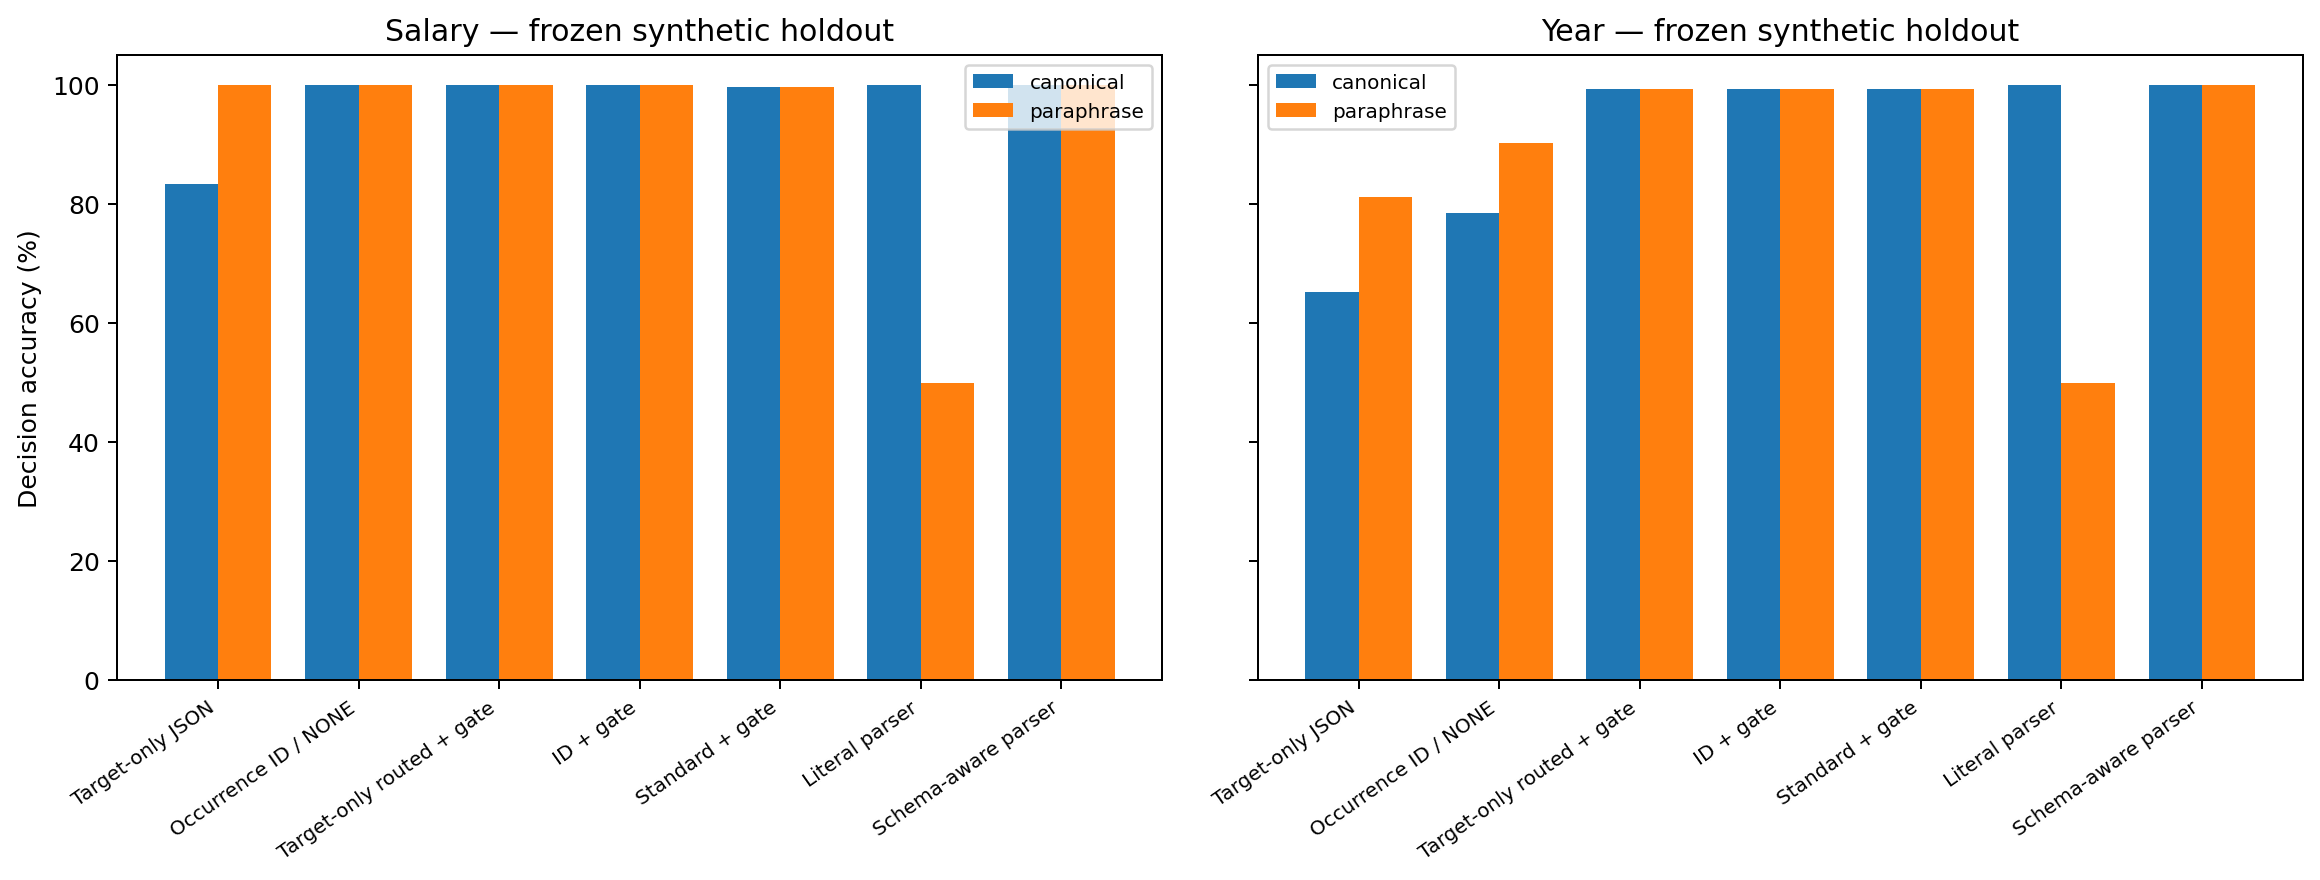

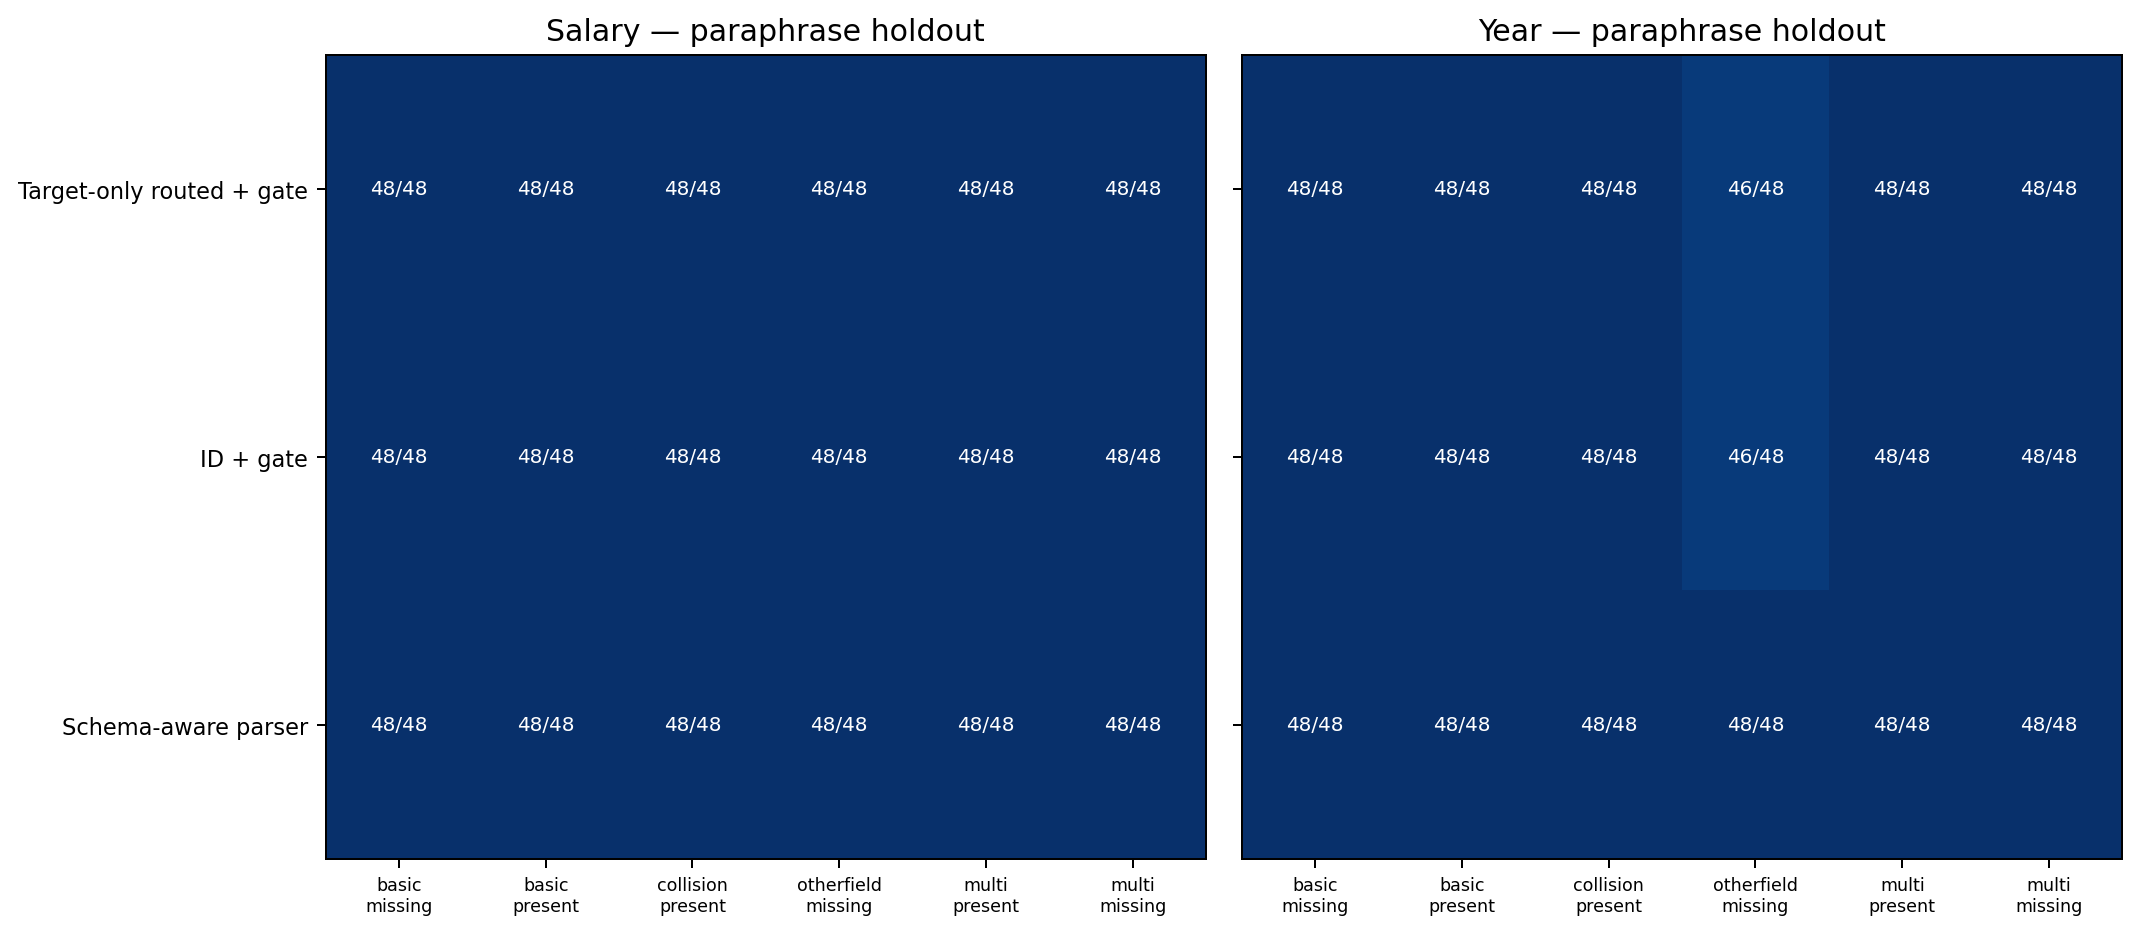

In [34]:
from IPython.display import Markdown, Image, display
status = json.loads((RUN_DIR / "status.json").read_text()) if (RUN_DIR / "status.json").exists() else {}
if status.get("status") == "COMPLETE":
    display(Markdown((RUN_DIR / "results/report_ko.md").read_text(encoding="utf-8")))
    display(Image(filename=str(RUN_DIR / "figures/holdout_accuracy.png")))
    display(Image(filename=str(RUN_DIR / "figures/holdout_conditions.png")))
else:
    print("추론·감사 완료 후 결과가 생성됩니다. status.json:", status)


In [35]:
from experiments.hw2_holdout_colab.runner import archive
result_zip = archive(RUN_DIR)
print("RESULT_ZIP:", result_zip)
print("VS Code 저장 위치 예: /home/cv/SSD0/jang/nlp/" + Path(result_zip).name)
try:
    from google.colab import files
    files.download(result_zip)
except Exception as exc:
    print("Colab 왼쪽 파일 패널에서 위 ZIP을 다운로드하세요:", type(exc).__name__)


RESULT_ZIP: /content/hw2_holdout/holdout_v1_results.zip
RESULT_ZIP: /content/hw2_holdout/holdout_v1_results.zip
VS Code 저장 위치 예: /home/cv/SSD0/jang/nlp/holdout_v1_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>